### Load Data

In [33]:
from data_pipeline import *
processed_data = load_data()
processed_data.head()

querying
data read
(2661381, 15)
converting discovery date
converting contained date
calculating duration
dropping unknown fires
dropped 270796 unknown ignition fires
fire cause classifications: ['Human' 'Natural']
Dropped 714 fires outside AK + lower 48


,fire_name,fire_year,nwcg_cause_classification,nwcg_general_cause,fire_size,fire_size_class,latitude,longitude,state,discovery_dt,cont_dt,duration_hours
0,FOUNTAIN,2005,Human,Power generation/transmission/distribution,0.10,A,40.036944,-121.005833,CA,2005-02-02 13:00:00,2005-02-02 17:30:00,4.50
1,PIGEON,2004,Natural,Natural,0.25,A,38.933056,-120.404444,CA,2004-05-12 08:45:00,2004-05-12 15:30:00,6.75
2,SLACK,2004,Human,Debris and open burning,0.10,A,38.984167,-120.735556,CA,2004-05-31 19:21:00,2004-05-31 20:24:00,1.05
3,DEER,2004,Natural,Natural,0.10,A,38.559167,-119.913333,CA,2004-06-28 16:00:00,2004-07-03 14:00:00,118.00
4,STEVENOT,2004,Natural,Natural,0.10,A,38.559167,-119.933056,CA,2004-06-28 16:00:00,2004-07-03 12:00:00,116.00


In [16]:
processed_data["nwcg_general_cause"].nunique()

13

### Load GACC boundaries and add region column

In [2]:
gacc = get_gacc()

GACC Regions: ['Alaska', 'Eastern Area', 'Great Basin', 'Northern California', 'Northern Rockies', 'Northwest', 'Rocky Mountain', 'Southern Area', 'Southern California', 'Southwest']
Polygon Bounds: [-179.23110125   24.3963123   179.85966573   71.43978571]


In [3]:
fires = join_geo_data(processed_data)

GACC Regions: ['Alaska', 'Eastern Area', 'Great Basin', 'Northern California', 'Northern Rockies', 'Northwest', 'Rocky Mountain', 'Southern Area', 'Southern California', 'Southwest']
Polygon Bounds: [-179.23110125   24.3963123   179.85966573   71.43978571]
Check for Duplicate Rows
Geo Dataset Rows: 2389871 | Input Dataset Rows: 2390071
Fires not in any GACC: 27
              fire_name  fire_year state   latitude   longitude
24100             LUCKY       2007    AZ  31.333056 -110.639444
25726             YAQUI       2007    AZ  31.333333 -110.320833
156200    SCHOOL CANYON       2003    AZ  31.333056 -110.390278
172077         MARIPOSA       2004    AZ  31.332500 -110.983056
213138        MEXICO #2       1994    AZ  31.334300 -109.786700
240120           CANE 3       1994    TX  29.209800 -102.890150
308805        COUNTY 19       2001    AZ  32.566400 -114.792700
308881            LEVEE       2005    AZ  32.691400 -114.734400
308916       WALKING EA       2005    AZ  32.700000 -114.730

#### Visualize GACC boundaries and fires

Saved GACC map to gacc_regions.png


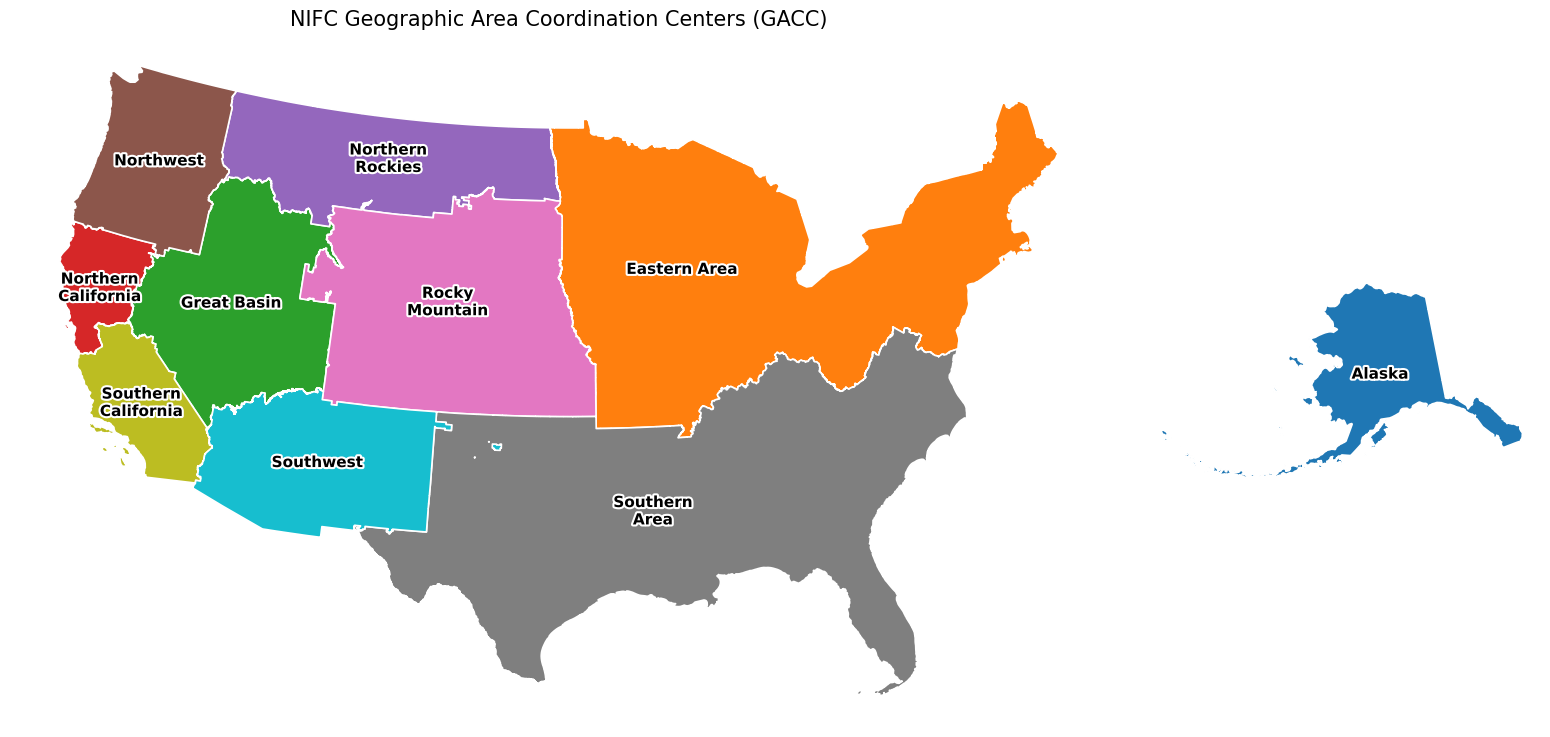

In [4]:
from visuals import gacc_map
display(gacc_map(gacc))

The small bit of Southwest blue in the Southern area in not an error, it is the national grasslands in Texas and Omaha Panhandles that the Southwest Agency is in charge of.

Scaling fires
Sorting fires
Creating fires map
Saved GACC fires map to gacc_fires.png


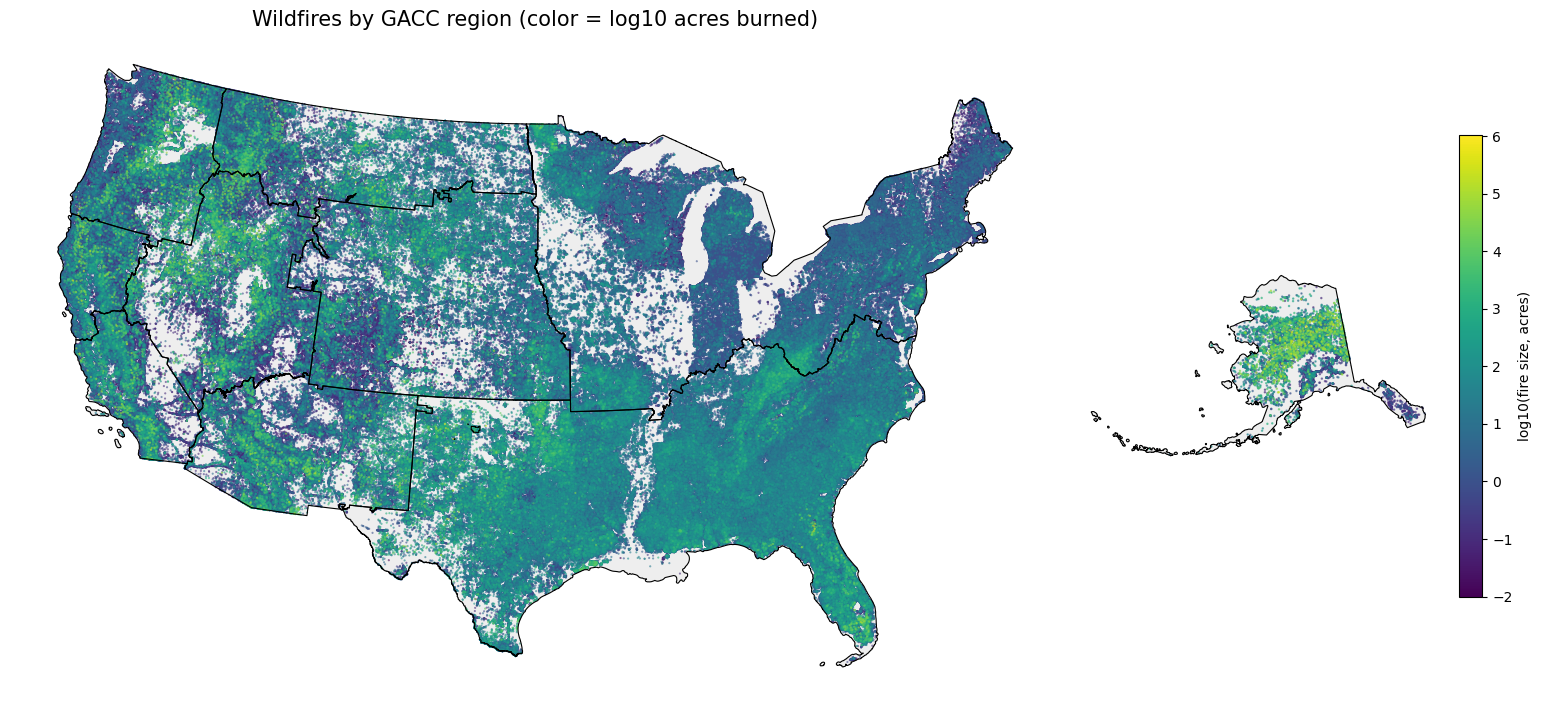

In [5]:
from visuals import gacc_fire_map

display(gacc_fire_map(fires, gacc))

### Mann-Whitney Statistical Testing

In [6]:
print(data_summary(fires))

                                             count    median          mean  \
nwcg_cause_classification fire_size_class                                    
Human                     A                 718860      0.10      0.115420   
                          B                1040549      1.00      2.086952   
                          C                 227781     20.00     28.367154   
                          D                  27404    150.00    161.232992   
                          E                  12107    457.00    506.043895   
                          F                   5225   1700.00   2027.980899   
                          G                   1750  10522.00  24157.380434   
Natural                   A                 193176      0.10      0.112120   
                          B                 109559      1.00      2.013746   
                          C                  31816     25.00     32.234953   
                          D                   7845    156.00    

In [7]:
import pandas as pd

national = mann_whitney_test(fires)
print("National Analysis")
print(national)

regional = pd.DataFrame({name: mann_whitney_test(g) for name, g in fires.groupby("gaccname")}).T


print("\nRegional Analysis")
print(regional[["n_human", "n_natural", "median_human", "median_natural",
                "p_value", "r_rb", "prob_superiority", "conclusion"]])


National Analysis
n_human                    2033676
n_natural                   356393
median_human                   1.0
median_natural                 0.2
U                   420263726941.0
p_value                        0.0
r_rb                      0.159687
prob_superiority          0.579844
conclusion            Human Larger
dtype: object

Regional Analysis
                     n_human n_natural median_human median_natural p_value  \
Alaska                 10572      5856          0.1         25.275     0.0   
Eastern Area          422340     15325          0.5           0.25     0.0   
Great Basin            39209     54221          0.3            0.1     0.0   
Northern California    79781     20322         0.25            0.1     0.0   
Northern Rockies       58883     40341          0.5            0.2     0.0   
Northwest              73403     50268          0.1            0.1     0.0   
Rocky Mountain        146445     43316          0.1            0.1     0.0   
Southern A

### Visualize Results

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


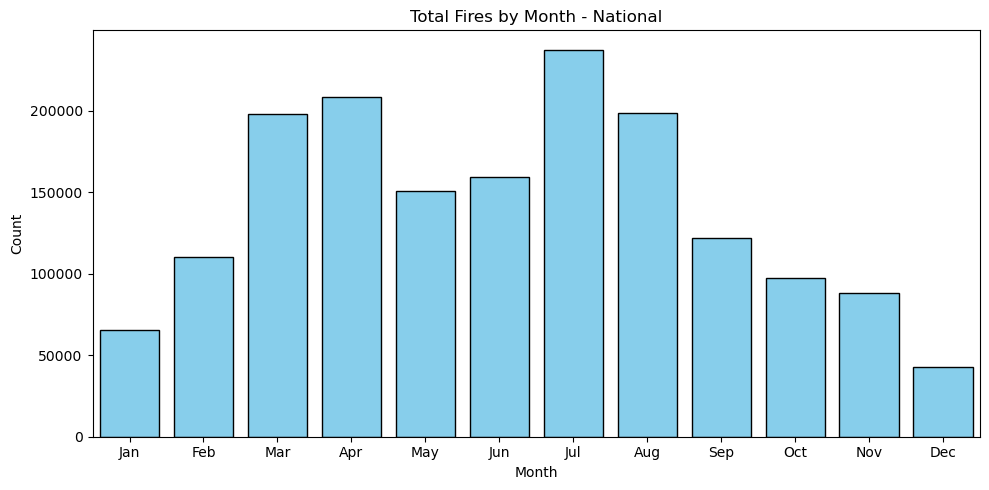

In [32]:
%load_ext autoreload
%autoreload 2
from visuals import *
display(plot_monthly_fires(fires, "National"))



The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


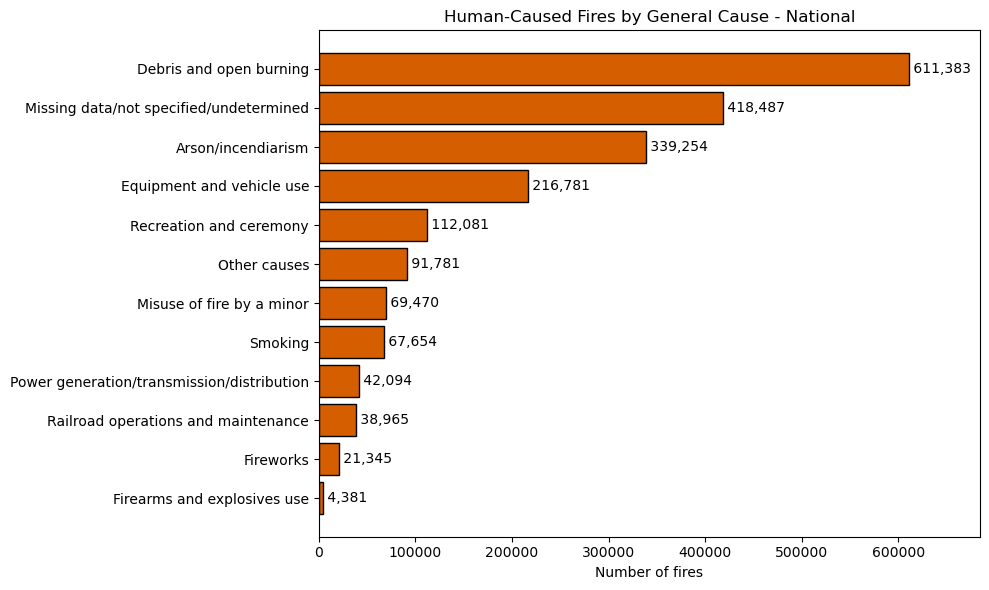

In [31]:
%load_ext autoreload
%autoreload 2
from visuals import *
display(human_cause_breakdown(fires, "National"))

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


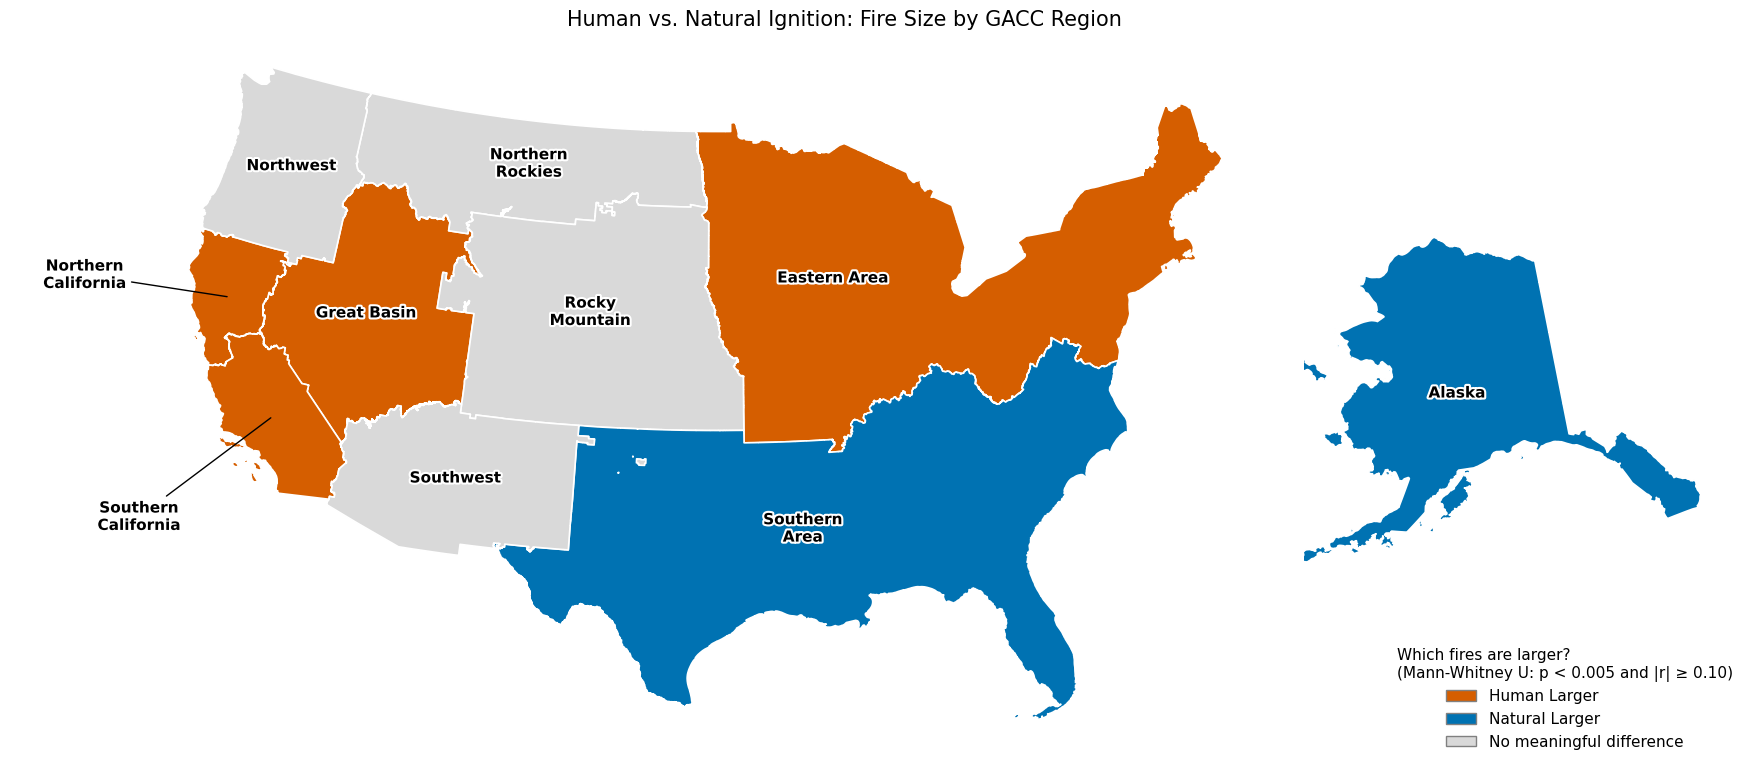

In [37]:
%load_ext autoreload
%autoreload 2
results_region_map(
    regional,
    legend_title="Which fires are larger?\n(Mann-Whitney U: p < 0.005 and |r| ≥ 0.10)",
    title="Human vs. Natural Ignition: Fire Size by GACC Region",
    gacc=gacc,
    )

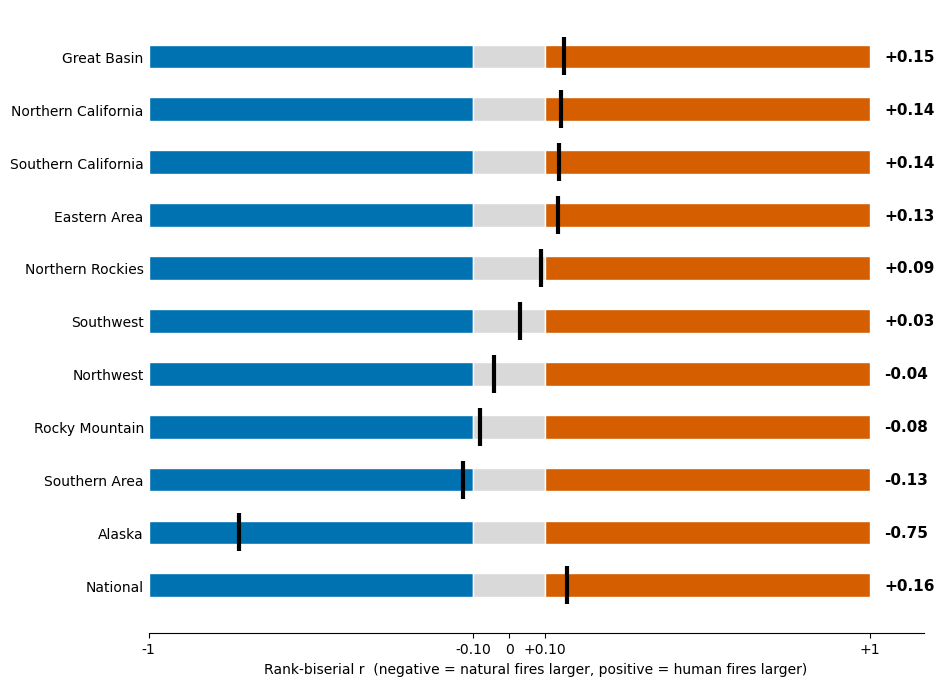

In [50]:
display(plot_r_bars(regional, r_min=0.10, national_r=national["r_rb"]))

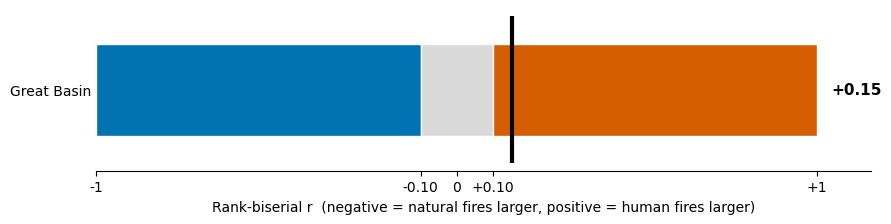

In [51]:
great_basin = regional.loc[["Great Basin"]]
display(plot_r_bars(great_basin, r_min=0.10))